# aaa

In [2]:
import numpy as np
from scipy.special import j0, j1, jn_zeros
from scipy.optimize import minimize
import matplotlib
#matplotlib.use("Agg")
import matplotlib.pyplot as plt

In [3]:
# ----------------------------------------------------------------------------
# 1. QUASI-DISCRETE HANKEL TRANSFORM (Guizar-Sicairos & Gutierrez-Vega)
#    H[f](kr) = int_0^R f(r) J0(kr r) r dr     (no 2*pi factor)
# ----------------------------------------------------------------------------
class QDHT:
    def __init__(self, R, n):
        z = jn_zeros(0, n + 1)
        a, S = z[:n], z[n]
        self.R, self.S, self.n = R, S, n
        self.r = a * R / S                      # radial nodes
        self.kr = a / R                         # spatial-frequency nodes
        J1 = np.abs(j1(a))
        self.T = (2.0 / S) * j0(np.outer(a, a) / S) / np.outer(J1, J1)
        self.fwd_pre, self.fwd_post = 1.0 / J1, J1 * R**2 / S
        self.inv_pre, self.inv_post = 1.0 / J1, J1 * S / R**2
        self.wq = 2 * R**2 / (S**2 * J1**2)     # quadrature: int g r dr ~ sum wq g

    def fwd(self, f):
        return self.fwd_post * (self.T @ (self.fwd_pre * f))

    def inv(self, F):
        return self.inv_post * (self.T @ (self.inv_pre * F))

    def power(self, f):                          # 2*pi int |f|^2 r dr
        return 2 * np.pi * np.sum(self.wq * np.abs(f) ** 2)



def transfer(z):
    return np.where(prop, np.exp(1j * kz * z), 0.0)

F=100
def propagate(U0, z=F):
    return Q.inv(transfer(z) * Q.fwd(U0))


def back_propagate(Uz, z=F):
    return Q.inv(np.conj(transfer(z)) * Q.fwd(Uz))

def target_intensity(rho):
    e = 2.0 if TARGET_IS_INTENSITY else 1.0
    return np.exp(-e * (rho / W_T) ** (2 * P_EXP))



# ----------------------------------------------------------------------------
# 3. STAGE A: RAY MAPPING (energy conservation, exact ray geometry)
# ----------------------------------------------------------------------------
def ray_mapping_phase():
    rf = np.linspace(0, R_MAX, 40001)
    cin = np.cumsum(np.exp(-2 * (rf / W_IN) ** 2) * rf)
    cin /= cin[-1]
    rho_f = np.linspace(0, 3 * W_T, 40001)
    ct = np.cumsum(target_intensity(rho_f) * rho_f)
    ct /= ct[-1]
    rho_of_r = np.interp(cin, ct, rho_f)               # monotone map r -> rho
    # transverse wave-vector of the ray joining (r,0) and (rho,f)  = d(phi_total)/dr
    d = rho_of_r - rf
    dphi_tot = K * d / np.sqrt(d**2 + F**2)
    dphi_lens = -K * rf / np.sqrt(rf**2 + F**2)
    dphi_doe = dphi_tot - dphi_lens
    phi_doe_f = np.concatenate([[0], np.cumsum(0.5 * (dphi_doe[1:] + dphi_doe[:-1]) * np.diff(rf))])
    return np.interp(r, rf, phi_doe_f)


# ----------------------------------------------------------------------------
# 4. FORWARD MODEL, LOSS, EXACT GRADIENT
# ----------------------------------------------------------------------------
def field_focus(phi_doe):
    return propagate(A_in * np.exp(1j * (phi_doe + phi_lens)))


def loss_and_grad(phi_doe):
    U0 = A_in * np.exp(1j * (phi_doe + phi_lens))
    Uf = P_F @ U0
    I = np.abs(Uf) ** 2
    L = np.sum(Q.wq * mask * (I - I_t) ** 2) / NORM
    g = 2 * Q.wq * mask * (I - I_t) / NORM                # dL/dI
    back = P_F.T @ (g * np.conj(Uf))
    grad = 2 * np.real(1j * U0 * back)
    return L, grad


def gerchberg_saxton(phi0, n_iter=200, outside=0.0):
    """Amplitude constraint inside ROI, outside field multiplied by `outside` (0 = hard zero)."""
    phi = phi0.copy()
    for _ in range(n_iter):
        Uf = field_focus(phi)
        Uf = np.where(r <= ROI, A_t * np.exp(1j * np.angle(Uf)), outside * Uf)
        U0 = back_propagate(Uf)
        ph = np.unwrap(np.angle(U0)) - phi_lens
        # keep a continuous branch relative to the previous iterate
        ph += 2 * np.pi * np.round((phi - ph).mean() / (2 * np.pi))
        phi = ph
    return phi


def optimize(phi0, maxiter=400):
    res = minimize(loss_and_grad, phi0, jac=True, method="L-BFGS-B",
                   options=dict(maxiter=maxiter, maxcor=30, ftol=1e-15, gtol=1e-12))
    return res.x, res


# ----------------------------------------------------------------------------
# 5. DIAGNOSTICS
# ----------------------------------------------------------------------------
def metrics(phi_doe, label=""):
    Uf = field_focus(phi_doe)
    I = np.abs(Uf) ** 2
    Ip = I / I.max()
    It = I_t / I_t.max()
    inside = r <= 1.2 * W_T
    rms = np.sqrt(np.sum(Q.wq[inside] * (Ip[inside] - It[inside]) ** 2) / np.sum(Q.wq[inside]))
    plateau = r <= 0.7 * W_T
    ripple = (Ip[plateau].max() - Ip[plateau].min()) / (Ip[plateau].max() + Ip[plateau].min())
    eff = 2 * np.pi * np.sum(Q.wq[r <= ROI] * I[r <= ROI]) / P_in
    print(f"{label:28s} rms err(r<1.2w)={rms:.4f}  plateau ripple(r<0.7w)={100*ripple:5.1f}%  "
          f"power in r<{ROI:.0f}mm = {100*eff:5.1f}% of input")
    return Uf


def rayleigh_sommerfeld(phi_doe, rho_pts, z=F, r_max=75.0, dr=0.04, n_phi=720):
    """Direct RS-I integral  U = (1/2pi) iint U0 (z/R^2)(1/R - ik) e^{ikR} dA  (valid for any z>0)."""
    rf = np.arange(dr / 2, r_max, dr)
    ph = np.interp(rf, r, phi_doe)                            # smooth, unwrapped
    U0 = np.exp(-(rf / W_IN) ** 2) * np.exp(1j * (ph - K * (np.sqrt(rf**2 + F**2) - F)))
    phis = (np.arange(n_phi) + 0.5) * np.pi / n_phi           # symmetry: integrate 0..pi and double
    out = []
    for rho in rho_pts:
        Rr = np.sqrt(rf[:, None] ** 2 + rho**2 - 2 * rf[:, None] * rho * np.cos(phis)[None, :] + z**2)
        ker = (z / Rr**2) * (1 / Rr - 1j * K) * np.exp(1j * K * Rr)
        ang = ker.sum(axis=1) * (np.pi / n_phi) * 2           # int_0^{2pi} dphi
        out.append(np.sum(U0 * ang * rf) * dr / (2 * np.pi))
    return np.array(out)

In [4]:
"""
1D (axisymmetric) DOE design for a flat-top (super-Gaussian) focal spot
=======================================================================
Device phase  :  phi_total(r) = phi_DOE(r) + phi_lens(r)
Lens phase    :  phi_lens(r)  = -k (sqrt(r^2 + f^2) - f)      (exact, not paraxial)
Propagation   :  exact scalar angular spectrum, written as a zeroth-order
                 Hankel transform (no Fresnel / Fraunhofer approximation)
Design        :  A) ray mapping  ->  B) Gerchberg-Saxton  ->  C) L-BFGS (analytic gradient)
Validation    :  direct Rayleigh-Sommerfeld I integral (independent of the Hankel code)

Units: millimetres everywhere.  Only numpy / scipy / matplotlib are needed.
"""

# ----------------------------------------------------------------------------
# 0. PARAMETERS  (edit here)
# ----------------------------------------------------------------------------
C_MM_GHZ = 299.792458          # c in mm * GHz
FREQ_GHZ = 300.0
WL = C_MM_GHZ / FREQ_GHZ       # wavelength [mm]  (~1 mm)
K = 2 * np.pi / WL
F = 100.0                      # focal distance [mm]
W_IN = 25.0                    # Gaussian input: amplitude exp(-(r/W_IN)^2)  (1/e^2 intensity radius)
W_T = 8.0                      # super-Gaussian target radius [mm]
P_EXP = 3                      # super-Gaussian exponent 2p = 6
TARGET_IS_INTENSITY = True     # True : I_t = exp(-2 (rho/W_T)^(2p))   False: I_t = exp(-(rho/W_T)^(2p))
R_MAX = 120.0                  # radius of the computational window [mm]
N = 800                        # Hankel nodes  (spacing ~ R_MAX/N = 0.15 mm = lambda/6.7)
ROI = 1.5 * W_T               # region where the target is enforced strongly
W_OUT = 1.0                    # relative loss weight outside ROI (area weighting is already physical)



Q = QDHT(R_MAX, N)
r = Q.r

# exact (scalar) angular-spectrum transfer function; evanescent waves dropped
kz2 = K**2 - Q.kr**2
prop = kz2 > 0
kz = np.sqrt(np.where(prop, kz2, 0.0))
H_F = transfer(F)




# Dense matrix of the propagator (needed for the adjoint in the gradient)
Id = np.eye(N)
P_F = np.array([propagate(Id[:, k]) for k in range(N)]).T  # P_F[n,k] = d U_f[n] / d U0[k]

# ----------------------------------------------------------------------------
# 2. INPUT FIELD, LENS, TARGET
# ----------------------------------------------------------------------------
A_in = np.exp(-(r / W_IN) ** 2)
phi_lens = -K * (np.sqrt(r**2 + F**2) - F)
P_in = Q.power(A_in)


# normalise target to carry the propagating power of the input
P_prop = Q.power(propagate(A_in * np.exp(1j * phi_lens)))
I_t = target_intensity(r)
I_t *= P_prop / (2 * np.pi * np.sum(Q.wq * I_t))
A_t = np.sqrt(I_t)

mask = np.where(r <= ROI, 1.0, W_OUT)
NORM = np.sum(Q.wq * mask * I_t**2)




# --- unit tests of the transform
f_test = np.exp(-(r / 10) ** 2)
print("QDHT round-trip error :", np.max(np.abs(Q.inv(Q.fwd(f_test)) - f_test)))
print("Gaussian power check  :", Q.power(f_test) / (np.pi * 100 / 2), "(should be 1)")
# gradient check
phi_t = np.random.randn(N) * 0.1
L0, g0 = loss_and_grad(phi_t)
e = np.zeros(N); e[37] = 1e-6
print("grad check (analytic vs FD):", g0[37], (loss_and_grad(phi_t + e)[0] - loss_and_grad(phi_t - e)[0]) / 2e-6)
print(f"lambda = {WL:.3f} mm, dr = {R_MAX/N:.3f} mm, beam-shaping beta = "
        f"{2*np.sqrt(2)*np.pi*W_IN*W_T/(WL*F):.1f}, propagating power fraction = {P_prop/P_in:.6f}\n")

# --- design
phi_A = ray_mapping_phase()
metrics(phi_A, "A) ray mapping")
phi_B = gerchberg_saxton(phi_A, n_iter=200, outside=0.0)
metrics(phi_B, "B) ray mapping + GS")
phi_C, res = optimize(phi_A)
metrics(phi_C, "C) ray mapping + L-BFGS")
phi_D, res2 = optimize(phi_B)
metrics(phi_D, "D) ray+GS + L-BFGS")
print("L-BFGS iterations:", res.nit, res2.nit, " final losses:", res.fun, res2.fun)

best = phi_C if res.fun < res2.fun else phi_D
np.save("doe_phase_1d.npy", np.vstack([r, best]))        # DOE phase (WITHOUT the lens) vs r

# --- independent validation with Rayleigh-Sommerfeld
rho_chk = np.linspace(0, 14, 29)
U_rs = rayleigh_sommerfeld(best, rho_chk)
U_h = np.interp(rho_chk, r, np.abs(field_focus(best)))
I_rs, I_h = np.abs(U_rs) ** 2, U_h**2
print(f"\nHankel-ASM vs direct RS integral: max |dI|/Imax = {np.max(np.abs(I_rs-I_h))/I_h.max():.2e}")

# --- plots
Uf = field_focus(best)
I = np.abs(Uf) ** 2

QDHT round-trip error : 1.0547118733938987e-14
Gaussian power check  : 0.9999999999999998 (should be 1)
grad check (analytic vs FD): 0.06872644947799325 0.068726457413959
lambda = 0.999 mm, dr = 0.150 mm, beam-shaping beta = 17.8, propagating power fraction = 1.000000

A) ray mapping               rms err(r<1.2w)=0.0397  plateau ripple(r<0.7w)= 15.2%  power in r<12mm = 100.0% of input
B) ray mapping + GS          rms err(r<1.2w)=0.0075  plateau ripple(r<0.7w)= 11.0%  power in r<12mm = 100.0% of input
C) ray mapping + L-BFGS      rms err(r<1.2w)=0.0004  plateau ripple(r<0.7w)= 10.6%  power in r<12mm = 100.0% of input
D) ray+GS + L-BFGS           rms err(r<1.2w)=0.0000  plateau ripple(r<0.7w)= 10.6%  power in r<12mm = 100.0% of input
L-BFGS iterations: 400 400  final losses: 1.101124214138217e-07 2.1958919030577978e-09

Hankel-ASM vs direct RS integral: max |dI|/Imax = 4.14e-04


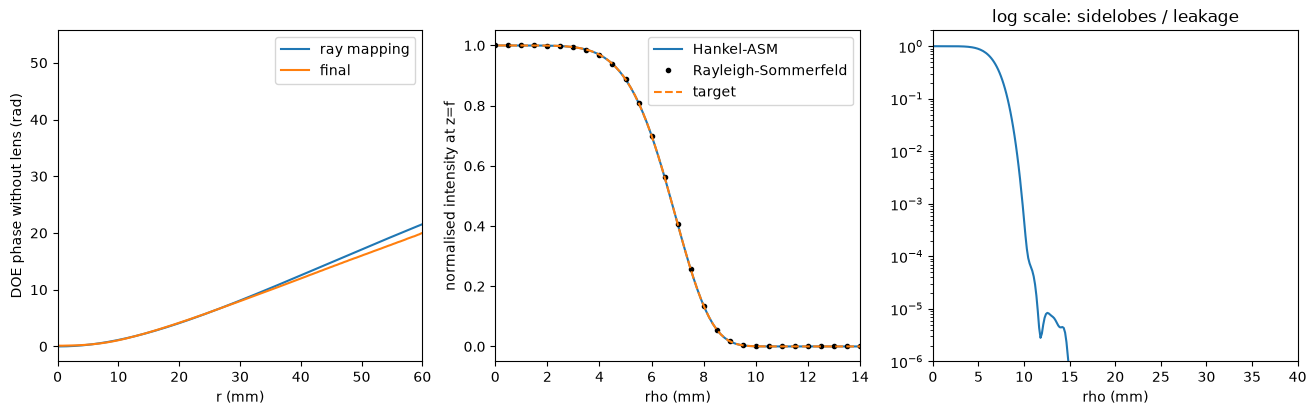

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].plot(r, phi_A, label="ray mapping"); ax[0].plot(r, best, label="final")
ax[0].set_xlim(0, 60); ax[0].set_xlabel("r (mm)"); ax[0].set_ylabel("DOE phase without lens (rad)"); ax[0].legend()
ax[1].plot(r, I / I.max(), label="Hankel-ASM"); ax[1].plot(rho_chk, I_rs / I_h.max(), "k.", label="Rayleigh-Sommerfeld")
ax[1].plot(r, I_t / I_t.max(), "--", label="target"); ax[1].set_xlim(0, 14)
ax[1].set_xlabel("rho (mm)"); ax[1].set_ylabel("normalised intensity at z=f"); ax[1].legend()
ax[2].semilogy(r, I / I.max() + 1e-12); ax[2].set_xlim(0, 40); ax[2].set_ylim(1e-6, 2)
ax[2].set_xlabel("rho (mm)"); ax[2].set_title("log scale: sidelobes / leakage")
#fig.show()
plt.show()
#plt.tight_layout(); plt.savefig("doe_design_1d.png", dpi=130)
#plt.tight_layout()
#fig.show()

240 GHz: peak I=7.0504  I(0)=6.6283  power in r<12mm=100.0%  peak-intensity best z=120 mm
270 GHz: peak I=6.9517  I(0)=6.8042  power in r<12mm=100.0%  peak-intensity best z=120 mm
300 GHz: peak I=6.8895  I(0)=6.8895  power in r<12mm=100.0%  peak-intensity best z=120 mm
330 GHz: peak I=7.0805  I(0)=6.9708  power in r<12mm=100.0%  peak-intensity best z=120 mm
360 GHz: peak I=7.2736  I(0)=7.1759  power in r<12mm=100.0%  peak-intensity best z=120 mm

200 GHz: rms vs target=0.054  half-max radius=6.36 mm  power outside r>12mm=0.00%
240 GHz: rms vs target=0.036  half-max radius=6.48 mm  power outside r>12mm=0.00%
300 GHz: rms vs target=0.000  half-max radius=6.70 mm  power outside r>12mm=0.00%
360 GHz: rms vs target=0.044  half-max radius=6.75 mm  power outside r>12mm=0.00%
400 GHz: rms vs target=0.077  half-max radius=6.73 mm  power outside r>12mm=0.00%


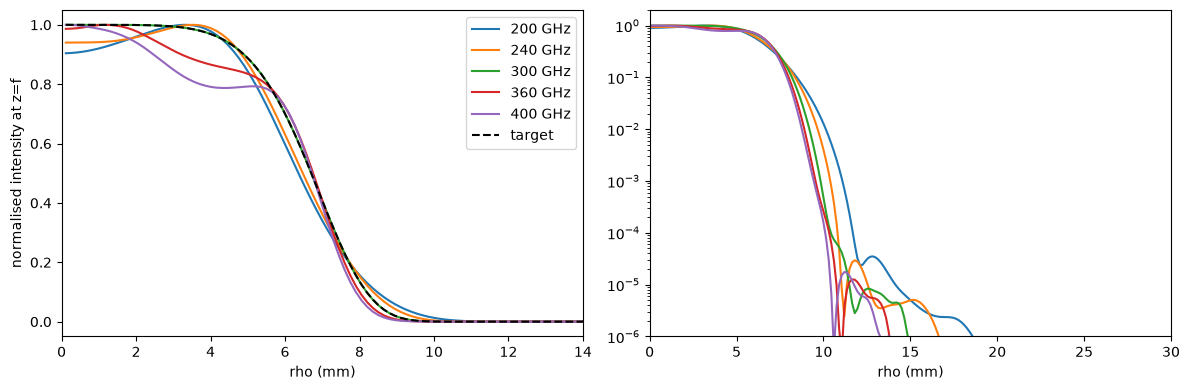

In [6]:
#r, Q = D.r, D.Q
#phi_doe0 = np.load("doe_phase_1d.npy")[1]        # DOE phase designed at 300 GHz (no lens)
#nu0 = D.FREQ_GHZ
phi_doe0 = best
nu0 = FREQ_GHZ

def focal_field(nu, z=F, n_ratio=1.0):
    """Field at distance z when the SAME device is illuminated at frequency nu (GHz).
    n_ratio = (n(nu)-1)/(n(nu0)-1): material dispersion of the relief (1.0 = none)."""
    k = 2*np.pi*nu/C_MM_GHZ
    phi_tot = (nu/nu0) * n_ratio * (phi_doe0 + phi_lens)     # fixed relief -> phase ∝ nu
    U0 = A_in * np.exp(1j*phi_tot)                           # same input beam shape (assumption)
    kz2 = k**2 - Q.kr**2
    H = np.where(kz2 > 0, np.exp(1j*np.sqrt(np.clip(kz2, 0, None))*z), 0)
    return Q.inv(H * Q.fwd(U0))

for nu in [240, 270, 300, 330, 360]:
    U = focal_field(nu); I = np.abs(U)**2
    P_in = Q.power(A_in)
    eff = 2*np.pi*np.sum(Q.wq[r<=ROI]*I[r<=ROI])/P_in
    # best focus along z
    zs = np.linspace(80, 120, 41)
    peak = [np.abs(focal_field(nu, z)).max()**2 for z in zs]
    print(f"{nu} GHz: peak I={I.max():.4f}  I(0)={I[0]:.4f}  power in r<12mm={100*eff:5.1f}%  "
          f"peak-intensity best z={zs[int(np.argmax(peak))]:.0f} mm")

It = I_t/I_t.max()
inside = r <= 1.2*W_T
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
print()
for nu in [200, 240, 300, 360, 400]:
    I = np.abs(focal_field(nu))**2; Ip = I/I.max()
    rms = np.sqrt(np.sum(Q.wq[inside]*(Ip[inside]-It[inside])**2)/np.sum(Q.wq[inside]))
    leak = 100*(1 - 2*np.pi*np.sum(Q.wq[r<=1.5*W_T]*I[r<=1.5*W_T])/Q.power(A_in))
    r50 = np.interp(0.5, Ip[::-1], r[::-1])
    print(f"{nu} GHz: rms vs target={rms:.3f}  half-max radius={r50:.2f} mm  power outside r>12mm={leak:.2f}%")
    ax[0].plot(r, Ip, label=f"{nu} GHz"); ax[1].semilogy(r, Ip+1e-9, label=f"{nu} GHz")
ax[0].plot(r, It, "k--", label="target"); ax[0].set_xlim(0, 14); ax[0].legend()
ax[0].set_xlabel("rho (mm)"); ax[0].set_ylabel("normalised intensity at z=f")
ax[1].set_xlim(0, 30); ax[1].set_ylim(1e-6, 2); ax[1].set_xlabel("rho (mm)")
#plt.tight_layout(); plt.savefig("doe_other_freq.png", dpi=130)
plt.tight_layout()
plt.show()

relief: h(0) = 0.2 mm, h(R_AP) = 1.1 mm; max surface slope = 79 deg (thin-element approx. needs <~10-15 deg)
central thickness in wavelengths: 0;   edge NA of the focusing ~ 0.51
ideal lossless thin element (design)           rms=0.000  transmitted power=100.0%  of which in r<12mm=100.0%
thin element + resin loss/Fresnel              rms=0.020  transmitted power= 71.8%  of which in r<12mm= 99.9%
  + height quantized to 0.05 mm layers         rms=0.024  transmitted power= 71.6%  of which in r<12mm= 99.8%
multislice best plane: z = h_max + 97.5 mm (design said 100 mm)
multislice through the relief (best plane)     rms=0.123  transmitted power= 80.0%  of which in r<12mm= 93.5%
multislice at nominal z = h_max + 100 mm       rms=0.138  transmitted power= 80.0%  of which in r<12mm= 93.4%
multislice, dz = 0.125 mm (convergence)        rms=0.110  transmitted power= 80.2%  of which in r<12mm= 93.0%


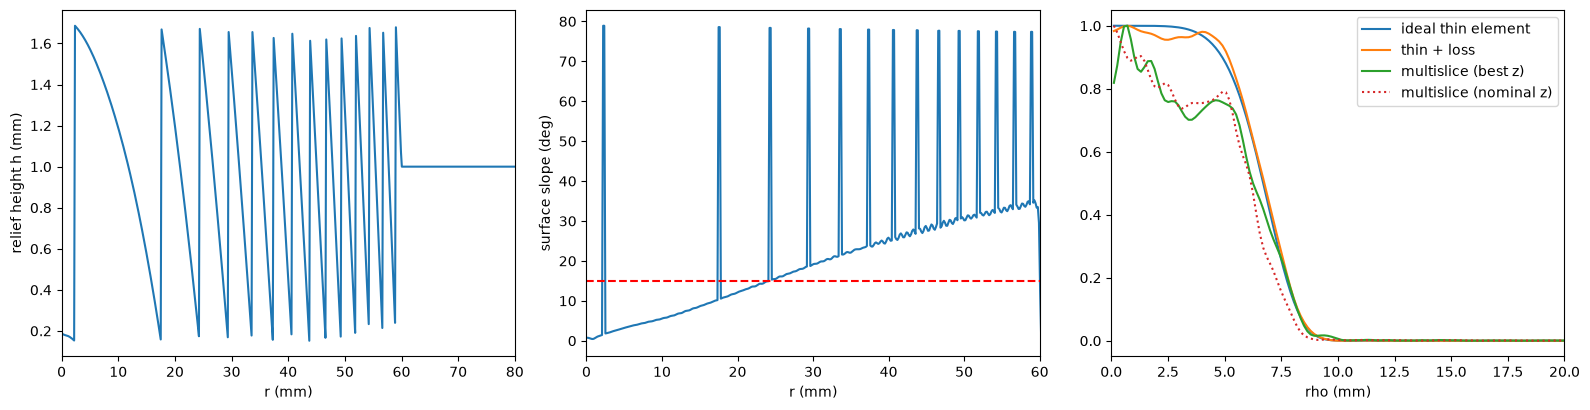

In [9]:
"""
Physical (resin relief) version of the 1D design.  Uses doe_design_1d.py (Hankel-ASM) and the saved DOE phase.
Material numbers below are PLACEHOLDERS -> replace with measured n(nu), tan(delta)(nu) of your resin.
Geometry: flat input face at z=0, relief exit surface z=h(r), incident beam from z<0.
"""
#Q, r = D.Q, r
N_RES, TAND = 1.65, 0.02          # resin index and loss tangent at 300 GHz
R_AP = 60.0                       # relief aperture [mm] (Gaussian intensity there ~1e-5)
H_EDGE = 1.0                      # minimum thickness at the aperture edge [mm]
LAYER, PIXEL = 0.05, 0.10         # printer layer height / lateral resolution [mm]
K0 = K

#phi_doe0 = np.load("doe_phase_1d.npy")[1]
phi_tot0 = phi_doe0 + phi_lens                       # total phase at 300 GHz (decreases outward)
# wrap phase
phi_tot0 = phi_tot0 % (2 * np.pi)


# ---- 1. phase -> relief height  (phase delay = k0 (n-1) h) ------------------------------------
ap = r <= R_AP
phi_edge = np.interp(R_AP, r, phi_tot0)
h = np.where(ap, H_EDGE + (phi_tot0 - phi_edge) / (K0 * (N_RES - 1)), H_EDGE)
slope = np.degrees(np.arctan(np.abs(np.gradient(h, r))))
print(f"relief: h(0) = {h[0]:.1f} mm, h(R_AP) = {h[ap][-1]:.1f} mm; max surface slope = {slope[ap].max():.0f} deg "
      f"(thin-element approx. needs <~10-15 deg)")
print(f"central thickness in wavelengths: {h[0]/WL:.0f};   edge NA of the focusing ~ {R_AP/np.hypot(R_AP, F):.2f}")


def quantize(h, layer=LAYER):
    return np.round(h / layer) * layer


# ---- 2. thin element with absorption and Fresnel loss -----------------------------------------
def thin_element(h, nu=FREQ_GHZ, n=N_RES, tand=TAND, z=F):
    k = 2 * np.pi * nu / C_MM_GHZ
    kappa = n * tand / 2                                        # Im(n)
    T_fres = 2 * n / (n + 1) ** 2 * np.sqrt(1.0) * 1.0          # amplitude transmission of the 2 surfaces
    t = (1 - ((n - 1) / (n + 1)) ** 2) * np.exp(1j * k * (n - 1) * h - k * kappa * h) * (h > 0)
    U0 = A_in * t                                              # (single-pass; no multiple reflections)
    kz2 = k**2 - Q.kr**2
    Hf = np.where(kz2 > 0, np.exp(1j * np.sqrt(np.clip(kz2, 0, None)) * z), 0)
    return Q.inv(Hf * Q.fwd(U0))


# ---- 3. multislice (split-step) propagation THROUGH the relief ---------------------------------
def multislice(h, nu=FREQ_GHZ, n=N_RES, tand=TAND, dz=0.25, z_obs=None):
    k = 2 * np.pi * nu / C_MM_GHZ
    kappa = n * tand / 2
    kz2 = k**2 - Q.kr**2
    kz = np.sqrt(np.clip(kz2, 0, None))
    Hs = np.where(kz2 > 0, np.exp(1j * kz * dz), 0)
    U = A_in.astype(complex)
    nsl = int(np.ceil(h.max() / dz))
    for j in range(nsl):                                         # thickness of resin inside slice j
        t = np.clip(h - j * dz, 0.0, dz)
        U = Q.inv(Hs * Q.fwd(U * np.exp(1j * k * (n - 1) * t - k * kappa * t)))
    zrem = z_obs - nsl * dz                                      # remaining free space to the observation plane
    Hr = np.where(kz2 > 0, np.exp(1j * kz * zrem), 0)
    return Q.inv(Hr * Q.fwd(U))


def report(U, label, P_in=Q.power(A_in)):
    I = np.abs(U) ** 2
    Ip, It = I / I.max(), I_t / I_t.max()
    ins = r <= 1.2 * W_T
    rms = np.sqrt(np.sum(Q.wq[ins] * (Ip[ins] - It[ins]) ** 2) / np.sum(Q.wq[ins]))
    tr = Q.power(U) / P_in
    inroi = 2 * np.pi * np.sum(Q.wq[r <= ROI] * I[r <= ROI]) / Q.power(U)
    print(f"{label:46s} rms={rms:.3f}  transmitted power={100*tr:5.1f}%  of which in r<12mm={100*inroi:5.1f}%")
    return Ip


if __name__ == "__main__":
    Ideal = field_focus(phi_doe0)
    report(Ideal, "ideal lossless thin element (design)")
    Ut = thin_element(h)
    Ip_t = report(Ut, "thin element + resin loss/Fresnel")
    Uq = thin_element(quantize(h))
    report(Uq, f"  + height quantized to {LAYER} mm layers")
    # multislice: observation plane referred to the apex of the thickest point, scanned for best focus
    best = None
    for zo in np.arange(h.max() + F - 25, h.max() + F + 25.1, 2.5):
        U = multislice(h, z_obs=zo)
        I = np.abs(U) ** 2; Ip = I / I.max(); It = I_t / I_t.max()
        ins = r <= 1.2 * W_T
        rms = np.sqrt(np.sum(Q.wq[ins] * (Ip[ins] - It[ins]) ** 2) / np.sum(Q.wq[ins]))
        if best is None or rms < best[0]:
            best = (rms, zo, U)
    zbest = best[1] - h.max()
    print(f"multislice best plane: z = h_max + {zbest:.1f} mm (design said {F:.0f} mm)")
    Ip_m = report(best[2], "multislice through the relief (best plane)")
    U_nom = multislice(h, z_obs=h.max() + F)
    Ip_n = report(U_nom, "multislice at nominal z = h_max + 100 mm")
    # convergence of the multislice step
    U_fine = multislice(h, dz=0.125, z_obs=best[1])
    report(U_fine, "multislice, dz = 0.125 mm (convergence)")

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    ax[0].plot(r, h); ax[0].set_xlim(0, 80); ax[0].set_xlabel("r (mm)"); ax[0].set_ylabel("relief height h (mm)")
    ax[1].plot(r, slope); ax[1].set_xlim(0, 60); ax[1].axhline(15, color="r", ls="--"); ax[1].set_xlabel("r (mm)")
    ax[1].set_ylabel("surface slope (deg)")
    ax[2].plot(r, np.abs(Ideal)**2/np.abs(Ideal).max()**2, label="ideal thin element")
    ax[2].plot(r, Ip_t, label="thin + loss"); ax[2].plot(r, Ip_m, label="multislice (best z)")
    ax[2].plot(r, Ip_n, ":", label="multislice (nominal z)"); ax[2].set_xlim(0, 20)
    ax[2].set_xlabel("rho (mm)"); ax[2].legend(); plt.tight_layout(); plt.savefig("physical_doe.png", dpi=130)